# Clustering

## Import Libraries

In [118]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

## Load Data

In [36]:
df = pd.read_csv('AI_Impact_on_Jobs_2030.csv')

# K-Means Clustering Analysis

## Business Goal

**Objective:** Discover natural groupings of jobs based on their characteristics (salary, experience, education, skills, AI exposure) to:
- Identify jobs with similar profiles that face comparable AI disruption patterns
- Find which combinations of skills, education, and experience create distinct job archetypes
- Understand if jobs with similar automation probabilities share other characteristics

**Key Questions:**
- Do high-paying jobs cluster together regardless of automation risk?
- Are there skill patterns that define certain job groups?
- Do jobs requiring similar experience/education face similar AI challenges?

**Expected Outcomes:**
- Skill profiles for each cluster
- Insights on which job characteristics correlate with AI vulnerability

## Feature Selecting

In [136]:
features_for_clustering = ['Average_Salary', 'Education_Numeric', 'Automation_Probability_2030']

X = df[features_for_clustering].copy()
X.shape

(2265, 3)

In [137]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=features_for_clustering)

X_scaled.head()

,Average_Salary,Education_Numeric,Automation_Probability_2030
0,1.285117,1.38618,-1.838597
1,1.655579,-1.04017,1.243247
2,1.376573,1.38618,0.391685
3,-0.528391,-1.04017,0.553887
4,0.536704,1.38618,-0.378776


## Optimal K
Finding the optimal number of clusters (K)

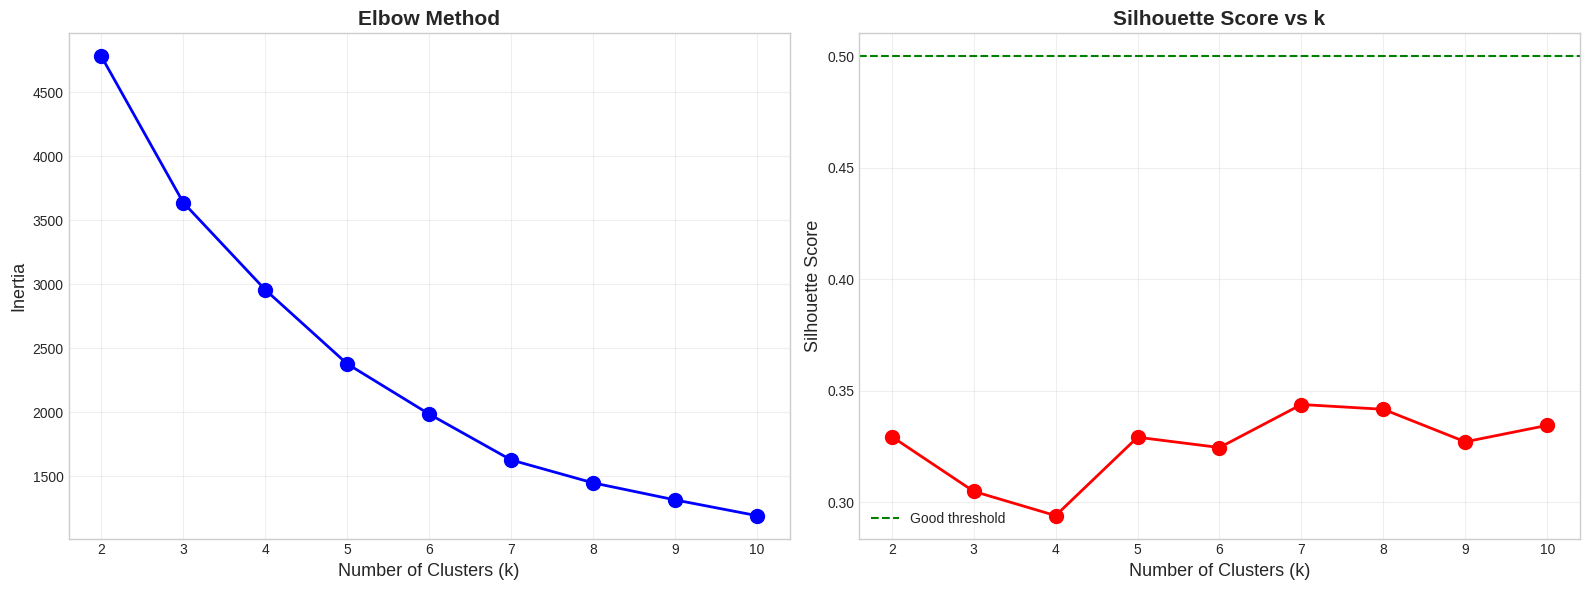

Recommended optimal k: 7 (Silhouette Score: 0.344)


In [138]:
inertias = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans_temp = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    kmeans_temp.fit(X_scaled)
    inertias.append(kmeans_temp.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans_temp.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.plot(K_range, inertias, 'bo-', linewidth=2, markersize=10)
ax1.set_xlabel('Number of Clusters (k)', fontsize=13)
ax1.set_ylabel('Inertia', fontsize=13)
ax1.set_title('Elbow Method', fontsize=15, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.set_xticks(K_range)

ax2.plot(K_range, silhouette_scores, 'ro-', linewidth=2, markersize=10)
ax2.set_xlabel('Number of Clusters (k)', fontsize=13)
ax2.set_ylabel('Silhouette Score', fontsize=13)
ax2.set_title('Silhouette Score vs k', fontsize=15, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.set_xticks(K_range)
ax2.axhline(y=0.5, color='green', linestyle='--', label='Good threshold')
ax2.legend()

plt.tight_layout()
plt.show()

optimal_k = K_range[silhouette_scores.index(max(silhouette_scores))]
print(f"Recommended optimal k: {optimal_k} (Silhouette Score: {max(silhouette_scores):.3f})")

## K Means

In [140]:
optimal_k = 7

kmeans = KMeans(n_clusters=optimal_k, init='k-means++', n_init=10, 
                max_iter=300, random_state=42)

clusters = kmeans.fit_predict(X_scaled)
df['Cluster'] = clusters

df['Cluster'].value_counts().sort_index()

Cluster
0    382
1    378
2    262
3    236
4    218
5    389
6    400
Name: count, dtype: int64

## Cluster Quality

In [141]:
silhouette_avg = silhouette_score(X_scaled, clusters)
davies_bouldin = davies_bouldin_score(X_scaled, clusters)
inertia = kmeans.inertia_

print(f"Silhouette Score: {silhouette_avg:.3f} (> 0.5 is good)")
print(f"Davies-Bouldin Index: {davies_bouldin:.3f} (lower is better)")
print(f"Inertia: {inertia:.2f}")

Silhouette Score: 0.344 (> 0.5 is good)
Davies-Bouldin Index: 0.909 (lower is better)
Inertia: 1626.75


## Visualize Clusters

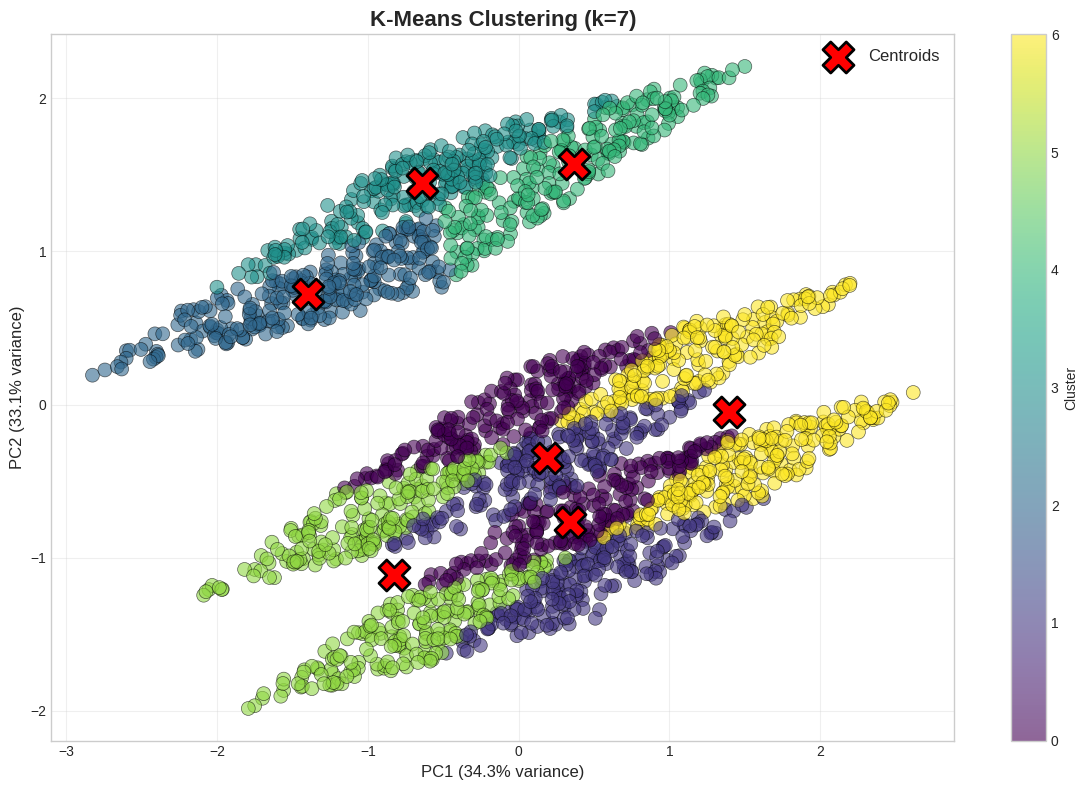

In [142]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(12, 8))

scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], 
                     c=clusters, cmap='viridis', 
                     alpha=0.6, edgecolors='black', linewidths=0.5, s=100)

centers_pca = pca.transform(kmeans.cluster_centers_)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1],
           s=500, c='red', marker='X', 
           edgecolors='black', linewidths=2,
           label='Centroids', zorder=5)

plt.title(f'K-Means Clustering (k={optimal_k})', fontsize=16, fontweight='bold')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)', fontsize=12)
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)', fontsize=12)
plt.colorbar(scatter, label='Cluster')
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Cluster Size

         Count  Percentage
Cluster                   
0          382       16.87
1          378       16.69
2          262       11.57
3          236       10.42
4          218        9.62
5          389       17.17
6          400       17.66


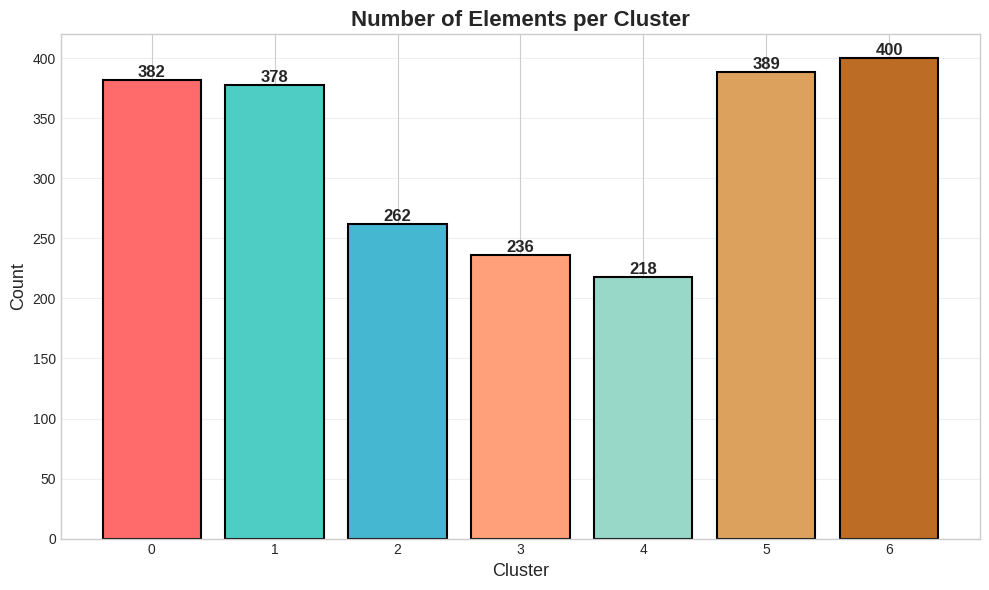

In [143]:
cluster_counts = df['Cluster'].value_counts().sort_index()
cluster_percentages = (cluster_counts / len(df) * 100).round(2)

summary_df = pd.DataFrame({
    'Count': cluster_counts,
    'Percentage': cluster_percentages
})

print(summary_df)

plt.figure(figsize=(10, 6))
bars = plt.bar(cluster_counts.index, cluster_counts.values, 
               color=['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A', '#98D8C8', '#DDA15E', '#BC6C25'][:optimal_k],
               edgecolor='black', linewidth=1.5)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
            f'{int(height)}',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.title('Number of Elements per Cluster', fontsize=16, fontweight='bold')
plt.xlabel('Cluster', fontsize=13)
plt.ylabel('Count', fontsize=13)
plt.xticks(cluster_counts.index)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## Statistical Analysis

In [144]:
for feature in features_for_clustering:
    print(f"\n{'='*60}")
    print(f"FEATURE: {feature}")
    print(f"{'='*60}")
    
    stats = df.groupby('Cluster')[feature].agg([
        ('Count', 'count'),
        ('Mean', 'mean'),
        ('Std Dev', 'std'),
        ('Min', 'min'),
        ('Max', 'max')
    ])
    
    print(stats.round(2))


FEATURE: Average_Salary
         Count       Mean   Std Dev    Min     Max
Cluster                                           
0          382   61158.87  18219.40  30030   91944
1          378  116023.29  17472.71  86862  149554
2          262  125670.75  15567.51  89151  149798
3          236   60108.25  18362.33  30060  101022
4          218   76354.81  27646.23  30234  141054
5          389  121014.35  17436.61  91284  149756
6          400   57367.46  16361.92  30318   86408

FEATURE: Education_Numeric
         Count  Mean  Std Dev  Min  Max
Cluster                                
0          382  1.52      0.5  1.0  2.0
1          378  1.50      0.5  1.0  2.0
2          262  4.00      0.0  4.0  4.0
3          236  4.00      0.0  4.0  4.0
4          218  4.00      0.0  4.0  4.0
5          389  1.49      0.5  1.0  2.0
6          400  1.47      0.5  1.0  2.0

FEATURE: Automation_Probability_2030
         Count  Mean  Std Dev   Min   Max
Cluster                                  
0     

# K-Means Clustering Analysis - Conclusions

## Cluster Interpretations

Based on the analysis of 2,265 jobs using Salary, Education, and Automation Probability:

**Cluster 0 - Low-Skilled, Low-Risk Jobs (17%)**
- Salary: ~$61k (lowest)
- Education: High School/Bachelor's (1.52)
- Automation Risk: 29% (LOW)
- Profile: Entry-level positions with lower pay but relatively safe from automation

**Cluster 1 - High-Skilled, High-Risk Jobs (17%)**
- Salary: ~$116k (high)
- Education: High School/Bachelor's (1.50)
- Automation Risk: 71% (HIGH)
- Profile: Well-paid jobs but highly vulnerable to AI/automation - likely technical roles that can be automated

**Cluster 2 - Elite, Low-Risk Jobs (12%)**
- Salary: ~$126k (highest)
- Education: PhD (4.0)
- Automation Risk: 45% (MEDIUM)
- Profile: Highly educated professionals (researchers, scientists) with good salaries and moderate AI resistance

**Cluster 3 - Elite, Low-Risk Jobs (10%)**
- Salary: ~$60k (low)
- Education: PhD (4.0)
- Automation Risk: 30% (LOW)
- Profile: Highly educated but lower-paid roles (academia, research) with low automation risk

**Cluster 4 - Elite, High-Risk Jobs (10%)**
- Salary: ~$76k (medium)
- Education: PhD (4.0)
- Automation Risk: 78% (VERY HIGH)
- Profile: Specialized roles vulnerable despite high education - possibly research/analysis that AI can perform

**Cluster 5 - Mid-Skilled, Low-Risk Jobs (17%)**
- Salary: ~$121k (high)
- Education: High School/Bachelor's (1.49)
- Automation Risk: 31% (LOW)
- Profile: Well-compensated jobs with lower education requirements and low automation threat

**Cluster 6 - Mid-Skilled, High-Risk Jobs (18%)**
- Salary: ~$57k (low)
- Education: High School/Bachelor's (1.47)
- Automation Risk: 71% (HIGH)
- Profile: Lower-paid jobs highly vulnerable to automation - likely routine, repetitive work

## Key Findings

1. **Education ≠ Safety**: Having a PhD (Clusters 2, 3, 4) doesn't guarantee protection from automation. Some highly educated roles face 78% automation risk.

2. **Salary Paradox**: High salary doesn't mean low risk. Cluster 1 earns $116k but faces 71% automation probability.

3. **Sweet Spot**: Cluster 5 represents the "ideal" - high salary (~$121k), low education requirements, and low automation risk (31%).

4. **Most Vulnerable**: Clusters 1, 4, and 6 face the highest automation risk (71-78%). These represent ~45% of all jobs analyzed.

5. **Safest Jobs**: Clusters 0, 3, and 5 have the lowest automation risk (29-31%), representing ~44% of jobs.

## Model Limitations

- Silhouette Score: 0.344 (moderate quality) - clusters overlap significantly
- Only 3 features used; including skills data might reveal different patterns